# Analyse de la réputation des entreprises à partir des avis clients

**Objectif** : prédire la polarité d'un avis (1 = positif, -1 = négatif) à partir de son texte, puis
s'en servir pour mesurer la réputation de chaque entreprise.

**Démarche** : la qualité du modèle dépend d'abord de la qualité des données. Le projet est donc
construit comme une chaîne complète :

`ingestion → contrôles qualité → nettoyage tracé → découpage sans fuite → modèles → évaluation → réputation → datamart`

Ce notebook présente les résultats. Le code est dans `src/` et tourne sans notebook
(`python -m src.pipeline`). Les sorties lues ici sont produites par ce pipeline.

In [1]:
import json, re, sqlite3, sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import load_config

cfg = load_config(ROOT / "config.yaml")
OUT, REPORTS = cfg["paths"]["outputs_dir"], cfg["paths"]["reports_dir"]
if not (OUT / "metrics.json").exists():
    raise SystemExit("Lancer d'abord : python -m src.pipeline")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)

## 1. Les données brutes

Source : *Trustpilot Reviews 123k* (licence MIT) — avis publics laissés sur des entreprises,
avec la note donnée par le client lui-même (1 à 5 étoiles). Le fichier est conservé tel quel
dans `data/raw/` avec son empreinte SHA-256 (`data/raw/SOURCE.md`).

In [2]:
raw = pd.read_csv(cfg["paths"]["raw"], dtype=str, keep_default_na=False)
print(f"{len(raw):,} avis, {raw['company'].nunique():,} entreprises, {raw['category'].nunique()} secteurs".replace(",", " "))
raw[["category", "company", "title", "review", "stars"]].head(3)

123 181 avis  1 680 entreprises  22 secteurs


,category,company,title,review,stars
0,Animals & Pets,ruffandtumbledogcoats.com,Great quality dog drying robe although…,Great quality dog drying robe although had to wait a while for it to come back into stock,5
1,Animals & Pets,ruffandtumbledogcoats.com,Really prompt service,"Really prompt service, The sofa covers have not moved since being put on despite the efforts of three cocker spaniels!Helpful staff who ...",5
2,Animals & Pets,ruffandtumbledogcoats.com,Life saver,I’ve purchased first of those coats in May2020. Still goes strong although my girl is not with us anymore her little sister is still usi...,5


### Un constat qui change l'interprétation : la source est échantillonnée par note

En profilant les données, on remarque qu'**aucune entreprise n'a plus de 20 avis pour une même note**,
et que toutes les entreprises à 100 avis en ont exactement 20 par niveau d'étoiles. Le jeu de données
a donc été constitué en prenant au plus 20 avis par note et par entreprise.

Conséquences :
- pour **entraîner** le modèle, c'est plutôt favorable (classes équilibrées, pas de sur-représentation des 5 étoiles) ;
- pour **mesurer la réputation**, les proportions de l'échantillon ne sont **pas** celles de la réalité :
  une entreprise avec 20 avis de chaque note ressort à 50 % de positifs, quelle que soit sa vraie réputation.

La méthode de calcul de réputation reste valable ; il faudrait simplement l'appliquer à l'ensemble des
avis réels de chaque entreprise (ce que fournirait un client).

In [3]:
per_note = pd.crosstab(raw["company"], raw["stars"])
print("Maximum d'avis pour une entreprise et une note :", per_note.values.max())
print("Entreprises avec exactement 20 avis pour chaque note :", int((per_note == 20).all(axis=1).sum()))
per_note.loc[["www.bbc.com", "www.thameswater.co.uk", "123sheets.co.uk", "101petexpress.com"]]

Maximum d'avis pour une entreprise et une note : 20
Entreprises avec exactement 20 avis pour chaque note : 558


stars,1,2,3,4,5
company,,,,,
www.bbc.com,20,20,19,11,20
www.thameswater.co.uk,20,20,20,20,20
123sheets.co.uk,10,10,19,19,20
101petexpress.com,0,0,0,1,20


## 2. Contrôle qualité et nettoyage

Chaque règle de nettoyage est nommée, comptée, et chaque ligne écartée part en **quarantaine**
(`data/rejected/`) avec un motif. Rien n'est supprimé en silence. Le rapport complet est dans
`reports/data_quality_report.md`.

Règles de gestion principales :
- **1-2 étoiles → -1, 4-5 étoiles → 1, 3 étoiles écartées** : un avis à 3 étoiles n'est ni positif ni négatif ;
  l'inclure d'un côté ou de l'autre ajouterait du bruit dans les labels ;
- **titre + avis** : le titre est ajouté devant l'avis uniquement s'il apporte une information ; quand il n'est
  que le début de l'avis tronqué par « … », l'ajouter compterait ces mots deux fois ;
- **langue** : les avis clairement écrits dans une autre langue que l'anglais sont écartés (heuristique
  explicable sur les mots-outils, sans dépendance externe) ;
- **doublons** : dédoublonnage sur un texte normalisé ; si des doublons ont des labels contradictoires,
  ils sont tous écartés (impossible de savoir lequel est juste) ;
- **ce qu'on ne fait PAS** : on ne supprime ni les mots-outils (« not good » ≠ « good ») ni les avis courts
  (« Never again » est un avis très clair).

In [4]:
q = json.loads((REPORTS / "data_quality_report.json").read_text(encoding="utf-8"))
avant, apres = q["avant_nettoyage"], q["après_nettoyage"]
keys = [k for k in avant if not isinstance(avant[k], dict)]
pd.DataFrame({"avant": [avant[k] for k in keys], "après": [apres.get(k) for k in keys]}, index=keys, dtype=object)

,avant,après
lignes,123181,101861
entreprises distinctes,1680,1680
secteurs distincts,22,22
avis par entreprise (médiane),89.0,72.0
avis par entreprise (max),100,80
textes vides,0,0
textes sans aucune lettre,2,0
longueur (car.) médiane,306.0,302.0
longueur (car.) p95,889.0,884.0
avis < 20 caractères,96,81


In [5]:
pd.DataFrame(q["journal_nettoyage"]).rename(columns={
    "step": "règle", "rows_in": "lignes en entrée", "rows_modified": "modifiées", "rows_rejected": "rejetées"})

,règle,lignes en entrée,modifiées,rejetées
0,titre ajouté devant l'avis (non redondant),123181,64413,0
1,normalisation du texte,123181,62343,0
2,note neutre écartée (règle de gestion),123181,0,21264
3,note hors du référentiel,101917,0,0
4,texte vide ou inexploitable,101917,0,0
5,"aucune lettre (ponctuation, chiffres ou émojis seuls)",101917,0,1
6,avis dans une autre langue que 'en',101916,0,42
7,doublons avec labels contradictoires (tous écartés),101874,0,0
8,doublons (1ère occurrence conservée),101874,0,13


Quelques exemples de textes avant / après normalisation :

In [6]:
clean = pd.read_parquet(cfg["paths"]["processed"])
pattern = r"[,!?][A-Za-z]|&[a-z]+;|([a-z])\1{3,}"   # ponctuation collée, entité HTML, lettres répétées
mask = clean["text_raw"].astype(object).map(lambda t: bool(re.search(pattern, t)))
ex = clean[clean["text_modified"] & mask]
ex[["text_raw", "text"]].sample(5, random_state=1)

,text_raw,text
58828,"Don’t be fooled by the online shop, especially when it says “in stock”Order within xzy & get next day delivery!!It’s not real ! Just vir...","Don't be fooled by the online shop, especially when it says ""in stock""Order within xzy & get next day delivery!! It's not real ! Just vi..."
72369,Good Service It was helpful to monitor the arrival…. It was helpful to monitor the arrival time by clicking the link on the email sent ...,Good Service It was helpful to monitor the arrival…. It was helpful to monitor the arrival time by clicking the link on the email sent b...
71383,Ordered 1 book on the 6th of February..it's now the 6th of March and still not delivered. I paid £5 delivery for this one book to Irelan...,Ordered 1 book on the 6th of February..it's now the 6th of March and still not delivered. I paid £5 delivery for this one book to Irelan...
34324,Had to have my radiators balanced.Two guys arrived(having phoned prior to visit)Politeful and very thorough and systematic.Even checking...,Had to have my radiators balanced. Two guys arrived(having phoned prior to visit)Politeful and very thorough and systematic. Even checki...
25449,"The hoover was delivered next day,but it was heavier than i wanted,so i let them know i didnt want it and could they swap it for a light...","The hoover was delivered next day, but it was heavier than i wanted, so i let them know i didnt want it and could they swap it for a lig..."


In [7]:
rejected = pd.read_csv(cfg["paths"]["rejected"])
display(rejected["reject_reason"].value_counts().rename("lignes en quarantaine").to_frame())
rejected[rejected["reject_reason"] == "wrong_language"][["language", "text_raw"]].head(6)

,lignes en quarantaine
reject_reason,
excluded_label,21264
wrong_language,42
duplicate,13
no_letters,1


,language,text_raw
1362,fr,Savana app bahot acha h bass price issue h thoda vrna quality bahot achi h savana app jb se use kr rhi hu mens myntra se mangwana chord ...
2614,fr,L inscription est simple maintenant à voir avec le temps
2615,fr,le moment rien à dire on attend la…. Pour le moment rien à dire on attend la suite cordialement
2616,fr,"J'ai commencé la la sķa furio.. J'ai déjà fait la moto Valentino rossi,pui la r5 turbo 2 de jean raniotti,les casque des plus grands pil..."
2617,fr,inscription très facile !hâte de commencer ce spider man maintenant !
2618,fr,Une très belle collection audio conte de la ferme. Nos petits enfants adorent jouer avec


## 3. Découpage train / validation / test sans fuite

- le dédoublonnage est fait **avant** le découpage : un même texte ne peut pas être à la fois en entraînement et en test ;
- le découpage est **groupé par entreprise** : les entreprises du test n'ont jamais été vues à l'entraînement.
  C'est la situation réelle (analyser une nouvelle entreprise), et cela empêche le modèle de « tricher » en
  apprenant le nom ou les produits d'une entreprise ;
- un contrôle bloquant arrête le pipeline si une fuite est détectée.

In [8]:
split = q["split"]
display(pd.DataFrame(split["splits"]).T)
print("Entreprises communes entre splits :", split["entités_partagées"], "| Textes communs :", split["textes_partagés"])

,avis,entités,pct_positifs
train,81895.0,1344.0,56.839856
val,10062.0,168.0,57.702246
test,9904.0,168.0,58.178514


Entreprises communes entre splits : 0 | Textes communs : 0


## 4. Comparaison des modèles

Même représentation pour tous (TF-IDF sur mots et bigrammes, pour capter « not good », « never again »…),
seul le classifieur change. On part d'une **référence naïve** (toujours prédire la classe majoritaire) :
un modèle qui ne la bat pas nettement n'a rien appris.

**Règle de sélection fixée à l'avance** : meilleur F1 macro sur la validation ; à moins de 0,005 près,
on préfère la régression logistique, qui donne une probabilité (utile pour le score de réputation) et
dont les poids sont interprétables. Le jeu de test n'est utilisé **qu'une fois**, pour le modèle retenu.

On utilise le **F1 macro** plutôt que l'accuracy parce que les classes ne sont pas parfaitement équilibrées
(~43 % / 57 %) : la référence naïve a 58 % d'accuracy mais un F1 macro de 0,37.

,modele,f1_macro,accuracy,roc_auc,temps_entrainement_s
0,svm_lineaire_C0.5,0.9297,0.9311,0.9777,10.8
1,logreg_C10,0.9293,0.9307,0.9775,10.3
2,logreg_C4,0.9276,0.9291,0.9772,10.6
3,logreg_C4_equilibre,0.9270,0.9282,0.9771,10.0
4,svm_lineaire_C0.1,0.9259,0.9274,0.9760,11.1
5,logreg_C1,0.9242,0.9258,0.9750,10.0
6,naive_bayes,0.9066,0.9078,0.9683,9.0
7,baseline_classe_majoritaire,0.3659,0.5770,NaN,9.5


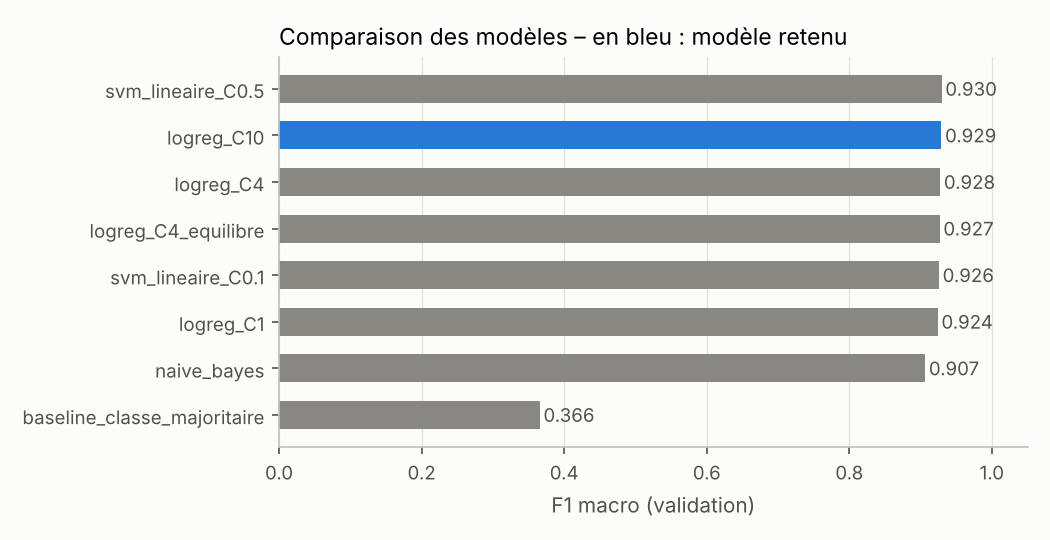

In [9]:
comp = pd.read_csv(OUT / "model_comparison.csv")
display(comp[["modele", "f1_macro", "accuracy", "roc_auc", "temps_entrainement_s"]].round(4)
        .sort_values("f1_macro", ascending=False).reset_index(drop=True))
Image(OUT / "figures" / "model_comparison.png")

Lecture :
- les modèles linéaires sont tous proches (0,92-0,93) : le gain viendra davantage des données que du choix du classifieur ;
- l'**équilibrage des classes** (`class_weight="balanced"`) n'apporte rien ici : le déséquilibre est modéré ;
- la SVM est très légèrement devant (moins de 0,001 de F1) mais ne donne pas de probabilité : la règle retient la régression logistique ;
- le meilleur C est en bord de grille (C = 10) : une piste simple est d'élargir la grille.

*Essai écarté* : ajouter des n-grammes de caractères (robustes aux fautes d'orthographe) sur un sous-échantillon de
40 000 avis fait passer le F1 macro de validation de 0,9232 à 0,9234, pour un temps d'entraînement 6 fois plus long.
Gain négligeable : non retenu.

## 5. Évaluation finale sur le jeu de test

In [10]:
m = json.loads((OUT / "metrics.json").read_text(encoding="utf-8"))
print("Modèle retenu :", m["modele_retenu"], "| entraîné sur :", m["entraine_sur"])
pd.Series(m["test"]).round(4).to_frame("test")

Modèle retenu : logreg_C10 | entraîné sur : train + validation


,test
accuracy,0.9355
f1_macro,0.9338
precision_negatif,0.9173
rappel_negatif,0.9295
f1_negatif,0.9234
precision_positif,0.9488
rappel_positif,0.9398
f1_positif,0.9443
roc_auc,0.9778


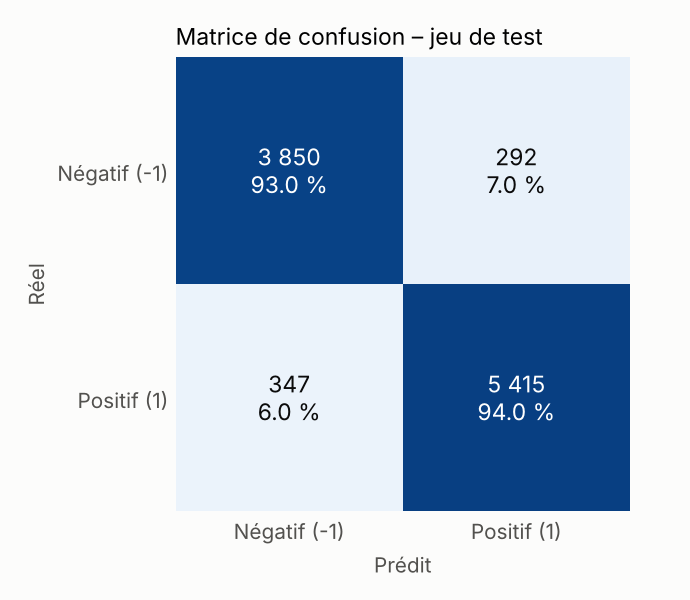

In [11]:
Image(OUT / 'figures' / 'confusion_matrix.png')

Où se trouvent les erreurs ? En croisant avec la note d'origine, on voit qu'elles se concentrent sur les
notes **intermédiaires** (2 et 4 étoiles), qui correspondent souvent à des avis nuancés :

In [12]:
pred = pd.read_parquet(OUT / "test_predictions.parquet")
pred["correct"] = pred["label"] == pred["pred"]
pred.groupby("label_raw")["correct"].agg(nb_avis="size", taux_bonnes_predictions="mean").round(3)

,nb_avis,taux_bonnes_predictions
label_raw,,
1,2316,0.966
2,1826,0.883
4,2535,0.888
5,3227,0.981


## 6. Interprétabilité : quels mots pèsent ?

Les poids de la régression logistique montrent ce que le modèle a appris. On retrouve des termes attendus
(« poor », « disappointed », « great », « easy »), et surtout **les négations** (« not », « not good »,
« not great ») : c'est la confirmation qu'il ne fallait pas supprimer les mots-outils.

On note aussi « 2 stars » et « 4 stars » : certains clients écrivent leur note dans le texte. C'est un signal
légitime (il est dans le texte), mais à garder en tête : sur des avis qui ne mentionnent pas de note, le modèle
s'appuiera sur le reste du vocabulaire.

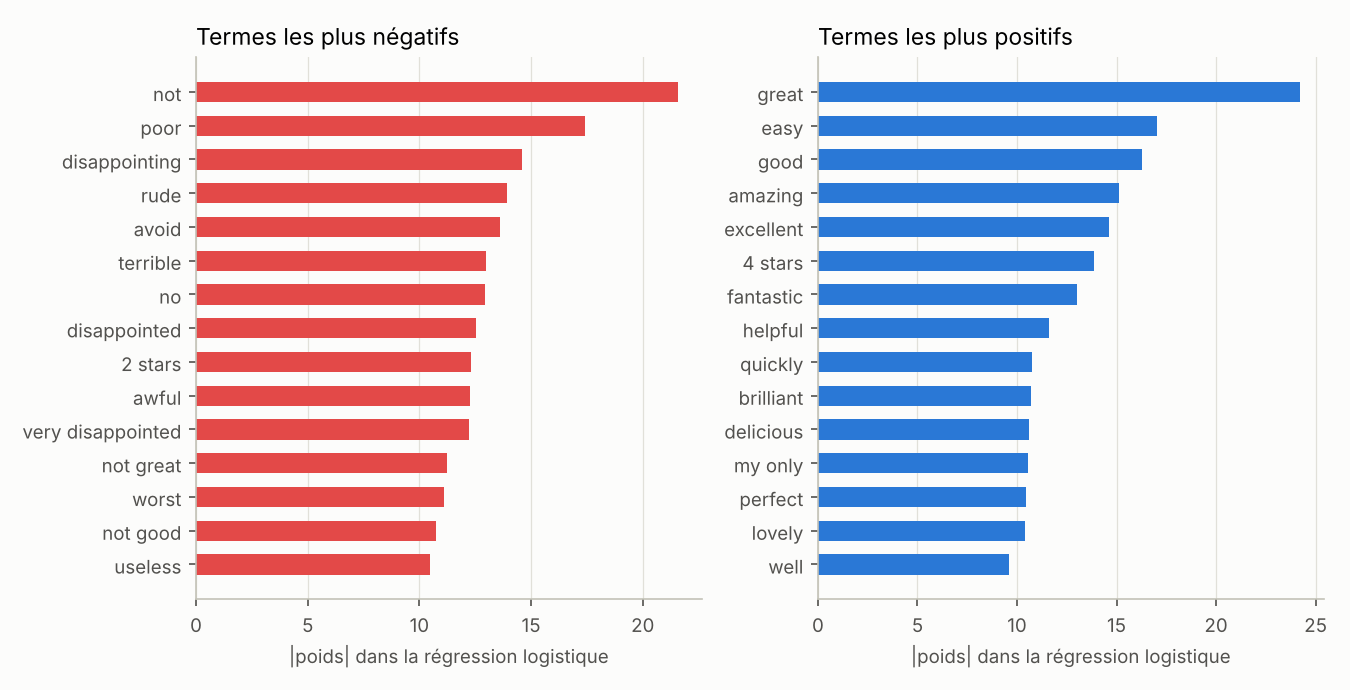

In [13]:
Image(OUT / 'figures' / 'top_features.png')

## 7. Analyse des erreurs

On relit les erreurs pour lesquelles le modèle était **le plus sûr de lui** : ce sont les plus instructives.

In [14]:
err = pd.read_csv(OUT / "error_analysis.csv")
err[["type_erreur", "confiance_erreur", "label", "text"]].head(25).round(3)

,type_erreur,confiance_erreur,label,text
0,faux positif,1.000,-1,"Absolutely brilliant service, really lovely vet who sorted out my dogs problem with great advice and reassurance. Highly recommended"
1,faux positif,1.000,-1,The tablets arrived very fast Excellent company to order from Thank you
2,faux positif,1.000,-1,Really pleased with how quickly the items came. They were packaged well. The items were exactly as described on the web site and good qu...
3,faux positif,1.000,-1,"BE SURE. About yesterday, it was good. Nice shoot, I arrived and the receptionist was kind. It was easy to understand and follow the ins..."
4,faux positif,1.000,-1,"Quick and easy purchase, downloaded antivirus and set up was very easy. Great buy , same again next year."
5,faux positif,0.999,-1,The shoot was amazing . It was my first photo shoot . I really enjoyed it .
6,faux positif,0.999,-1,Yorkshire. I am very happy with what you have sent me Very quick service and very well packed Thank you
7,faux positif,0.999,-1,"Excellent service, quick turnround"
8,faux positif,0.999,-1,"Is a very nice course, the course is so clear and easy to understand"
9,faux positif,0.999,-1,"Shoot Experience. It was nice experience being my first time at the studio, you guys are great the camara is perfect and precise , to me..."


Constats :
- **une grande partie de ces erreurs sont des erreurs de label, pas du modèle** : des textes clairement positifs
  (« Absolutely brilliant service… Highly recommended ») notés 1 ou 2 étoiles, et l'inverse. Ce sont probablement
  des erreurs de clic ou des notes inversées. Le modèle a raison, la donnée a tort : ces avis faussent aussi
  l'évaluation (vers le bas) ;
- **avis nuancés** : « Good experience… but I was not informed of later charges » commence bien et se termine mal ;
- **mises à jour** : « *Update* » où le client change d'avis au cours du texte ;
- **contexte** : sur certaines entreprises (média), les avis portent sur un débat d'opinion plutôt que sur le service.

Piste concrète : utiliser ces incohérences note / texte comme un **contrôle qualité** (liste d'avis à vérifier),
c'est une application directe du modèle pour la gouvernance des données.

## 8. De l'avis à la réputation de l'entreprise

Le besoin n'est pas de classer des avis un par un, mais de mesurer la réputation des entreprises.
On agrège donc les prédictions par entreprise (et par secteur) :
- **part d'avis positifs prédits** ;
- **score de réputation = borne basse de Wilson** (intervalle de confiance à 95 %) : une entreprise à 3 avis
  positifs sur 3 n'est pas « meilleure » qu'une entreprise à 90 % sur 200 avis. La borne basse pénalise les
  petits volumes et permet un classement honnête ;
- un score n'est publié qu'à partir d'un nombre minimum d'avis (`reputation.min_reviews`).

**Validation pour ce besoin** : sur des entreprises jamais vues, la part de positifs prédite suit-elle la réelle ?

,valeur
entreprises_test,168.000000
entreprises_publiables,163.000000
seuil_avis,20.000000
correlation_predit_reel,0.981322
ecart_absolu_moyen_points,2.465712
ecart_absolu_max_points,16.455696
secteurs,22.000000


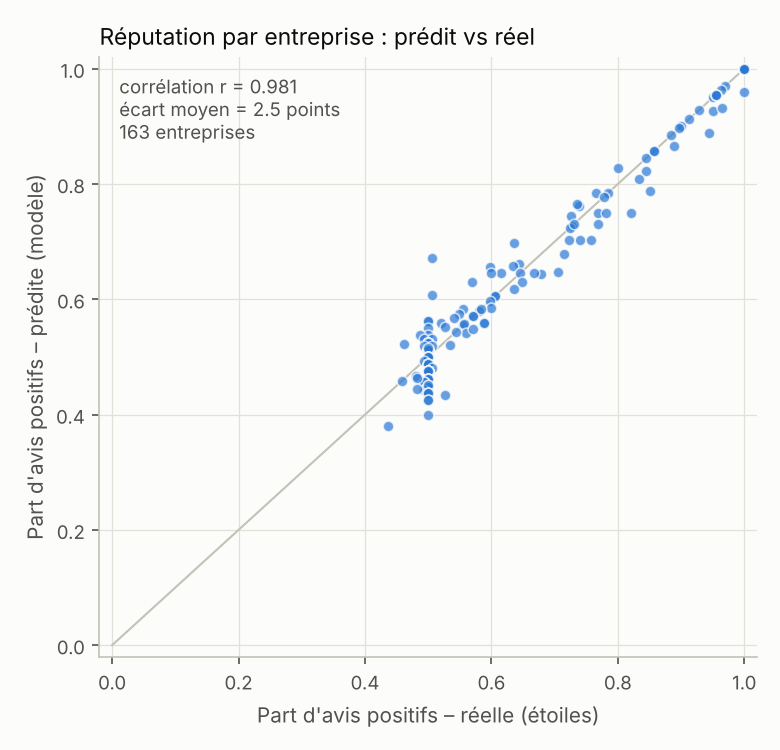

In [15]:
s = json.loads((OUT / "reputation_summary.json").read_text(encoding="utf-8"))
display(pd.Series(s).to_frame("valeur"))
Image(OUT / "figures" / "reputation_pred_vs_true.png")

La corrélation est très forte et l'écart moyen faible : **le modèle est fiable pour mesurer une réputation
agrégée**, même quand il se trompe sur quelques avis individuels (les erreurs se compensent en partie).

Le nuage regroupé autour de 50 % s'explique par l'échantillonnage de la source (20 avis par note) vu en partie 1.
Pour la même raison, le classement ci-dessous illustre la méthode mais **ne reflète pas la vraie réputation** de ces entreprises.

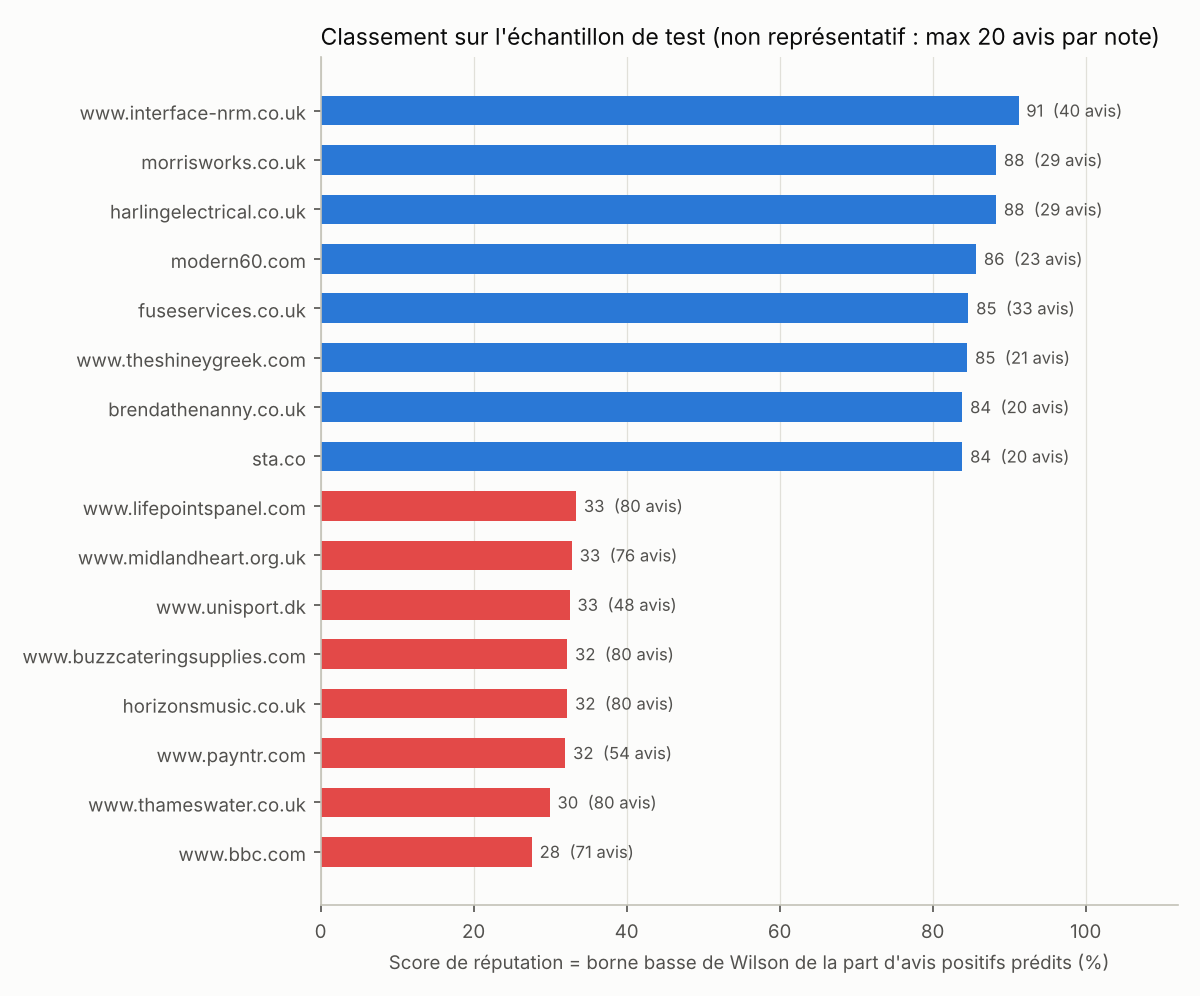

In [16]:
Image(OUT / 'figures' / 'reputation_ranking.png')

In [17]:
pd.read_csv(OUT / "reputation_by_category.csv")[
    ["entity_category", "nb_avis", "part_positifs_predite", "part_positifs_reelle", "score_reputation_wilson"]].round(3)

,entity_category,nb_avis,part_positifs_predite,part_positifs_reelle,score_reputation_wilson
0,Hobbies & Crafts,394,0.731,0.726,0.685
1,Business Services,301,0.698,0.701,0.644
2,Public & Local Services,634,0.656,0.667,0.618
3,Education & Training,322,0.630,0.627,0.576
4,Restaurants & Bars,378,0.619,0.646,0.569
5,Shopping & Fashion,465,0.613,0.613,0.568
6,Electronics & Technology,450,0.607,0.598,0.561
7,Animals & Pets,507,0.590,0.598,0.546
8,Home Services,758,0.587,0.586,0.552
9,Legal Services & Government,255,0.576,0.569,0.515


## 9. Mise à disposition pour la BI : un datamart en étoile

Les résultats sont chargés dans une base SQLite (`outputs/reputation_datamart.sqlite`) :
- `dim_entreprise` : une ligne par entreprise (secteur, description — qui était répétée sur chaque avis dans la source) ;
- `fait_avis` : une ligne par avis (note source, label réel, prédiction, probabilité) ;
- vues `v_reputation_entreprise` et `v_reputation_secteur`, prêtes pour un outil de reporting.

Des contrôles de cohérence sont exécutés après chargement (nombre de lignes, clés orphelines, totaux des vues).

In [18]:
with sqlite3.connect(cfg["paths"]["datamart"]) as con:
    top = pd.read_sql("""
        SELECT secteur, nb_entreprises, nb_avis, part_positifs_predite, part_positifs_reelle
        FROM v_reputation_secteur ORDER BY part_positifs_predite DESC LIMIT 5""", con)
top

,secteur,nb_entreprises,nb_avis,part_positifs_predite,part_positifs_reelle
0,Hobbies & Crafts,10,394,0.7310,0.7259
1,Business Services,7,301,0.6977,0.7010
2,Public & Local Services,14,634,0.6562,0.6672
3,Education & Training,6,322,0.6304,0.6273
4,Restaurants & Bars,9,378,0.6190,0.6455


## 10. Utiliser le modèle sur de nouveaux avis

Le modèle sauvegardé (`models/sentiment_model.joblib`) **embarque le nettoyage du texte** : on lui donne le
texte brut, il applique exactement la même transformation qu'à l'entraînement. Cela évite l'erreur classique
d'un prétraitement différent entre entraînement et production.

In [19]:
from src.predict import load_model, predict
model = load_model(cfg)
predict(model, [
    "Delivery was quick and the staff were really helpful, will order again!",
    "Not good at all. Parcel arrived damaged and nobody answered my emails.",
    "Not bad, but the price went up without any warning.",
])

,texte,polarite,proba_positif
0,"Delivery was quick and the staff were really helpful, will order again!",1,0.998
1,Not good at all. Parcel arrived damaged and nobody answered my emails.,-1,0.002
2,"Not bad, but the price went up without any warning.",-1,0.066


## 11. Limites et pistes d'amélioration

**Limites**
- source échantillonnée (20 avis max par note et par entreprise) : les proportions par entreprise ne sont pas réelles ;
- bruit dans les labels (note incohérente avec le texte) : il pénalise à la fois l'entraînement et l'évaluation ;
- avis en anglais uniquement (Royaume-Uni majoritairement) : un modèle pour des avis en français ou en darija
  demanderait des données labellisées dans ces langues ;
- la classe « neutre » (3 étoiles) est écartée : le modèle force tout avis en positif ou négatif.

**Pistes**
- élargir la grille de C et tester une calibration des probabilités ;
- un modèle pré-entraîné (BERT, CamemBERT pour le français) : gain attendu sur les avis nuancés, au prix d'un coût
  de calcul bien plus élevé — à comparer à la référence actuelle ;
- détecter automatiquement les incohérences note / texte comme contrôle qualité ;
- suivre la performance dans le temps (dérive du vocabulaire) en réévaluant périodiquement sur des avis récents notés ;
- passer de 2 à 3 classes (positif / neutre / négatif) si le métier en a besoin.